In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv('../Data/Insurance.csv')
df_clean = df.copy()

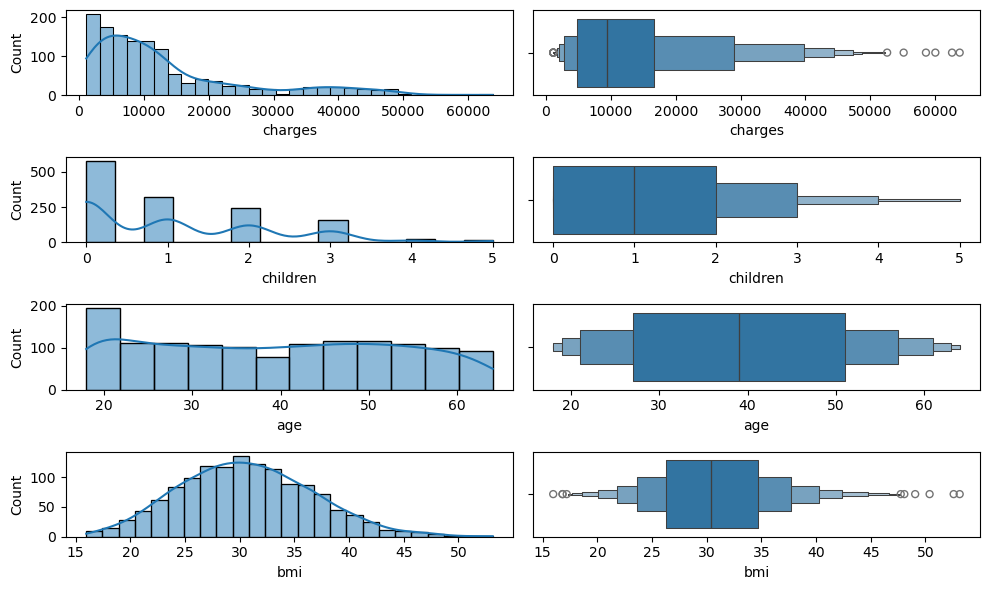

In [3]:
fig, ax = plt.subplots(4, 2, figsize=(10, 6))

sns.histplot(x=df['charges'], kde=True, ax=ax[0, 0])
sns.boxenplot(x=df['charges'], ax=ax[0, 1])

sns.histplot(x=df['children'], kde=True, ax=ax[1, 0])
sns.boxenplot(x=df['children'], ax=ax[1, 1])

sns.histplot(x=df['age'], kde=True, ax=ax[2, 0])
sns.boxenplot(x=df['age'], ax=ax[2, 1])

sns.histplot(x=df['bmi'], kde=True, ax=ax[3, 0])
sns.boxenplot(x=df['bmi'], ax=ax[3, 1])

plt.tight_layout()

age -> its flat and widespread, needs min max scaler

bmi -> its bell curve, gotta delete outliers w z score, and do standard scaler

charges -> heavily right-skewed, needs to go through z score and to be flattened a bit using ln(x)

In [4]:
# age
scaler = MinMaxScaler()
df_clean[['age']] = scaler.fit_transform(df_clean[['age']])

In [5]:
display(df.describe(), df_clean.describe())

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,0.461022,30.663397,1.094918,13270.422265
std,0.305434,6.098187,1.205493,12110.011237
min,0.000000,15.960000,0.000000,1121.873900
25%,0.195652,26.296250,0.000000,4740.287150
50%,0.456522,30.400000,1.000000,9382.033000
75%,0.717391,34.693750,2.000000,16639.912515
max,1.000000,53.130000,5.000000,63770.428010


In [6]:
X = df_clean.drop(columns=['charges'])
y = df_clean['charges']

ct = ColumnTransformer([
    ("encoder", OneHotEncoder(drop='first'), ['sex', 'smoker', 'region'])
    ],
    remainder='passthrough',
    verbose_feature_names_out=False
)

X_encoded = np.array(ct.fit_transform(X))

X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

y_train = np.log1p(y_train)

In [7]:
model = LinearRegression()
model.fit(X_train, y_train)
model.score(X_test, np.log1p(y_test))

0.8047410791393022